<h1 align = "Center">
Lotus Group Customer Value & Profitability Analysis

<h2 align = "Center">
Business Impact and Recommendations
</h2>
</h1>

The previous notebooks told us **where** profit comes from and **where** it is lost. This notebook answers the question a business owner asks next:

> *"If we act on this, how much is it worth?"*

**Research question 5:** *How much profit would discount limits have protected in 2024?*

We also put figures on the opportunities the customer segments reveal. Every estimate uses **2024**, the most recent full year, and the assumptions behind it are stated alongside, so a reader can judge how much weight to put on each number.

| Type of estimate | What it means |
|---|---|
| **Measured** | Calculated directly from 2024 transactions, such as profit lost to deep discounts |
| **Scenario** | Depends on how customers react, so we show a range from cautious to optimistic |
| **Illustrative** | Depends on campaign results we can't observe, so we give simple "if X%, then Y" figures |

# Setup and Data Loading

In [1]:
import pandas as pd
from pathlib import Path

data_path = Path("../01_Data/processed")
features_path = Path("../01_Data/features")
outputs_path = Path("../01_Data/outputs")
images_path = Path("../05_Images")
images_path.mkdir(parents=True, exist_ok=True)

sales = pd.read_csv(data_path / "sales_clean.csv", parse_dates=["order_date"])
segments = pd.read_csv(outputs_path / "customer_segments.csv")
order_flags = pd.read_csv(outputs_path / "order_risk_flags_2024.csv", parse_dates=["order_date"])

sales_2024 = sales[sales["order_date"].dt.year == 2024].copy()

revenue_2024 = sales_2024["line_revenue"].sum()
profit_2024 = sales_2024["line_profit"].sum()
print(f"2024 revenue: EGP {revenue_2024:,.0f}")
print(f"2024 profit:  EGP {profit_2024:,.0f}  ({profit_2024 / revenue_2024:.1%} margin)")

2024 revenue: EGP 13,652,094
2024 profit:  EGP 2,883,744  (21.1% margin)

In [2]:
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter

NAVY = "#00274B"
ELECTRONICS = "#2B79B8"
CLOTHING = "#B5508C"
LOSS = "#C2410C"
MUTED = "#6B7280"
thousands = FuncFormatter(lambda v, _: f"{v / 1e3:,.0f}k")

plt.rcParams.update({
    "figure.figsize": (9, 4.5),
    "axes.spines.top": False,
    "axes.spines.right": False,
    "axes.grid": True,
    "axes.axisbelow": True,
    "grid.color": "#e6e5e0",
    "grid.linewidth": 0.8,
    "axes.edgecolor": "#a3a29c",
    "axes.titleweight": "bold",
    "axes.titlesize": 12,
    "lines.linewidth": 2,
})

# Opportunity 1: Cap Electronics Discounts

### What deep Electronics discounts cost in 2024 (measured)

The exploratory analysis showed that Electronics break even at 20% off and lose money beyond it. We start by measuring what discounts above each possible cap actually earned in 2024.

In [3]:
electronics_2024 = sales_2024[sales_2024["category"] == "Electronics"]

current = pd.DataFrame([
    {
        "discount above": f"{cap}%",
        "lines": int((electronics_2024["discount_pct"] > cap).sum()),
        "revenue": electronics_2024.loc[electronics_2024["discount_pct"] > cap, "line_revenue"].sum(),
        "profit": electronics_2024.loc[electronics_2024["discount_pct"] > cap, "line_profit"].sum(),
    }
    for cap in (10, 15, 20)
]).set_index("discount above")
current["share of 2024 revenue"] = current["revenue"] / revenue_2024

current.style.format({"revenue": "EGP {:,.0f}", "profit": "EGP {:,.0f}",
                      "share of 2024 revenue": "{:.1%}"})

,lines,revenue,profit,share of 2024 revenue
discount above,,,,
10%,207,"EGP 2,555,390","EGP 10,390",18.7%
15%,107,"EGP 1,460,165","EGP -55,435",10.7%
20%,55,"EGP 697,125","EGP -56,375",5.1%


In 2024, Electronics sold at more than 15% off brought in **EGP 1.46M of revenue but lost EGP 55,000**. The business gave away margin and then some.

### What a discount cap would have changed (scenario)

Suppose Lotus Group had capped Electronics discounts at a given level. We can't know for certain how customers would have reacted, so we model a range:

| Scenario | Assumption |
|---|---|
| **Optimistic** | Every customer still buys at the capped discount (100% kept) |
| **Middle** | Half of those sales still happen (50% kept) |
| **Cautious** | Every one of those sales is lost (0% kept) |

For the sales that are kept, we reprice them at the cap: the list price minus the capped discount, with the same product cost.

In [4]:
import numpy as np

def cap_scenario(cap, share_kept):
    affected = electronics_2024[electronics_2024["discount_pct"] > cap]
    capped_revenue = (affected["unit_price"] * (1 - cap / 100) * affected["quantity"]).sum()
    capped_profit = capped_revenue - affected["line_cost"].sum()
    profit_change = share_kept * capped_profit - affected["line_profit"].sum()
    revenue_change = share_kept * capped_revenue - affected["line_revenue"].sum()
    return profit_change, revenue_change

scenario_rows = []
for cap in (10, 15, 20):
    for label, kept in [("Optimistic (100% kept)", 1.0), ("Middle (50% kept)", 0.5),
                        ("Cautious (0% kept)", 0.0)]:
        profit_change, revenue_change = cap_scenario(cap, kept)
        scenario_rows.append({"cap": f"Cap at {cap}%", "scenario": label,
                              "profit change": profit_change, "revenue change": revenue_change})

scenarios = pd.DataFrame(scenario_rows)
scenarios["profit change vs 2024"] = scenarios["profit change"] / profit_2024

scenarios.pivot(index="cap", columns="scenario", values="profit change")[
    ["Cautious (0% kept)", "Middle (50% kept)", "Optimistic (100% kept)"]
].style.format("EGP {:+,.0f}")

scenario,Cautious (0% kept),Middle (50% kept),Optimistic (100% kept)
cap,,,
Cap at 10%,"EGP -10,390","EGP +150,900","EGP +312,190"
Cap at 15%,"EGP +55,435","EGP +104,158","EGP +152,880"
Cap at 20%,"EGP +56,375","EGP +57,185","EGP +57,995"


In [5]:
scenarios.pivot(index="cap", columns="scenario", values="revenue change")[
    ["Cautious (0% kept)", "Middle (50% kept)", "Optimistic (100% kept)"]
].style.format("EGP {:+,.0f}")

scenario,Cautious (0% kept),Middle (50% kept),Optimistic (100% kept)
cap,,,
Cap at 10%,"EGP -2,555,390","EGP -1,121,600","EGP +312,190"
Cap at 15%,"EGP -1,460,165","EGP -653,642","EGP +152,880"
Cap at 20%,"EGP -697,125","EGP -319,565","EGP +57,995"


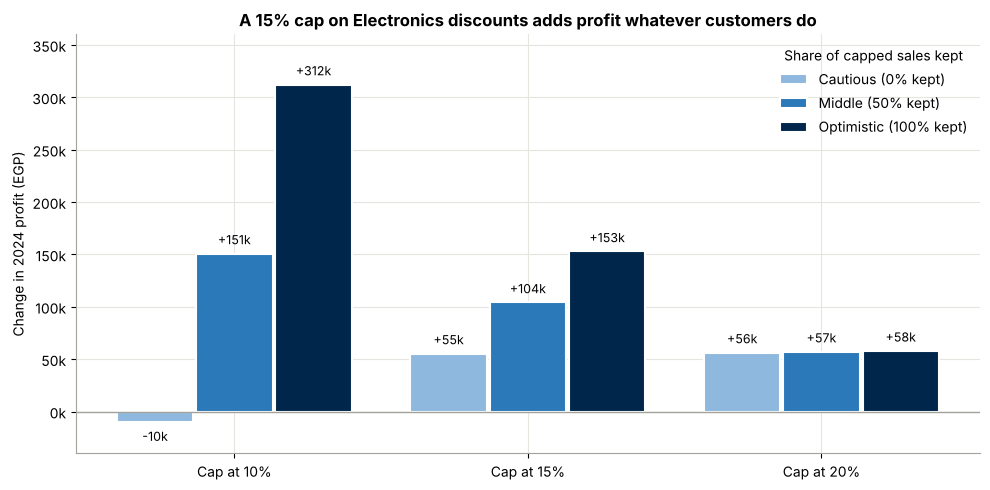

In [6]:
caps = ["Cap at 10%", "Cap at 15%", "Cap at 20%"]
order = ["Cautious (0% kept)", "Middle (50% kept)", "Optimistic (100% kept)"]
colors = ["#8FB8DE", ELECTRONICS, NAVY]
pivot = scenarios.pivot(index="cap", columns="scenario", values="profit change").loc[caps, order]

fig, ax = plt.subplots(figsize=(10, 5))
x = np.arange(len(caps))
width = 0.26
for i, (scenario, color) in enumerate(zip(order, colors)):
    values = pivot[scenario].to_numpy()
    bars = ax.bar(x + (i - 1) * (width + 0.01), values, width, color=color, label=scenario,
                  edgecolor="white", linewidth=1.5)
    for bar, v in zip(bars, values):
        ax.text(bar.get_x() + bar.get_width() / 2, v + (6_000 if v >= 0 else -6_000),
                f"{v / 1e3:+,.0f}k", ha="center", va="bottom" if v >= 0 else "top", fontsize=9)
ax.axhline(0, color="#a3a29c", linewidth=1)
ax.set_xticks(x, caps)
ax.yaxis.set_major_formatter(thousands)
ax.set_ylabel("Change in 2024 profit (EGP)")
ax.set_ylim(-40_000, 360_000)
ax.set_title("A 15% cap on Electronics discounts adds profit whatever customers do")
ax.legend(title="Share of capped sales kept", frameon=False, loc="upper right")
plt.tight_layout()
plt.savefig(images_path / "discount_cap_scenarios.png", dpi=150, bbox_inches="tight")
plt.show()

**Reading the scenarios:**

- **Cap at 15% (recommended):** profit rises by **EGP 55,000 to EGP 153,000** a year, **in every scenario**, because sales above 15% off were losing money anyway. Even if every one of those customers walked away, the business would be better off.
- **Cap at 10%:** the biggest gain if customers accept it (up to **EGP 312,000**), but it also caps 15% discounts, which are still profitable. If most of those customers leave, the gain disappears, and if all leave it turns into a small loss. It is a bigger bet.
- **Cap at 20%:** safe but timid. It only removes the 25–30% discounts and leaves the break-even 20% discounts in place.

The **15% cap** is the "no-regret" choice: it can't make things worse, and it can add up to about **5% to annual profit**. The revenue at stake is at most 11% of 2024 revenue, and only in the worst case where every one of those customers leaves.

In [7]:
cap15 = scenarios[scenarios["cap"] == "Cap at 15%"].set_index("scenario")
print("Cap at 15%: change in 2024 profit")
for scenario in order:
    row = cap15.loc[scenario]
    print(f"  {scenario:24s} EGP {row['profit change']:+10,.0f}  ({row['profit change vs 2024']:+.1%})")

Cap at 15%: change in 2024 profit
  Cautious (0% kept)       EGP    +55,435  (+1.9%)
  Middle (50% kept)        EGP   +104,158  (+3.6%)
  Optimistic (100% kept)   EGP   +152,880  (+5.3%)

# Opportunity 2: Approval Check for Risky Orders (measured)

Some deep discounts may still be needed, for example to clear old stock or to match a competitor. For those exceptions, the decision tree from the previous notebook acts as a **safety net**: it flags orders likely to lose money so a manager can approve or reprice them.

In [8]:
flag_summary = order_flags.groupby(["flagged", "loss_making"]).agg(
    orders=("order_id", "size"), profit=("order_profit", "sum")
)
flag_summary

orders     profit
flagged loss_making                   
False   0              3483  2912528.0
        1                 2     -518.0
True    0                13    12174.0
        1                38   -40439.5

In [9]:
caught_losses = -order_flags.loc[order_flags["flagged"] & (order_flags["loss_making"] == 1), "order_profit"].sum()
missed_losses = -order_flags.loc[~order_flags["flagged"] & (order_flags["loss_making"] == 1), "order_profit"].sum()
orders_reviewed = int(order_flags["flagged"].sum())

print(f"Orders flagged for review in 2024: {orders_reviewed} of {len(order_flags):,} "
      f"(about {orders_reviewed / 52:.0f} a week across 15 stores)")
print(f"Losses on flagged orders (protectable): EGP {caught_losses:,.0f}")
print(f"Losses the check would have missed:      EGP {missed_losses:,.0f}")

Orders flagged for review in 2024: 51 of 3,536 (about 1 a week across 15 stores)
Losses on flagged orders (protectable): EGP 40,440
Losses the check would have missed:      EGP 518

- The check flags about **one order a week** across the whole chain, a very light workload.
- If flagged orders had been repriced to at least break even, Lotus Group would have avoided **about EGP 40,000** of losses in 2024.
- With the 15% cap in place, most of these orders would no longer happen. The approval check is the **control for exceptions**, so a manager can still approve a deep discount knowingly rather than by accident.

*These EGP 40,000 overlap with the cap's savings (they are largely the same orders), so the two figures should not be added together.*

# Opportunity 3: Act on the Customer Segments (illustrative)

The segments tell us **who** to focus on. How much a campaign earns depends on response rates we can't observe, so we give simple "if X%, then Y" figures built only from each segment's own 2024 behaviour.

In [10]:
sales_2024_segments = sales_2024.merge(segments[["customer_id", "segment"]], on="customer_id", how="left")

per_customer_2024 = (
    segments.groupby("segment")["customer_id"].count().rename("customers").to_frame()
    .join(sales_2024_segments.groupby("segment").agg(
        profit_2024=("line_profit", "sum"),
        orders_2024=("order_id", "nunique"),
    ))
    .fillna(0)
)
per_customer_2024["profit_per_customer_2024"] = per_customer_2024["profit_2024"] / per_customer_2024["customers"]
per_customer_2024["profit_per_order_2024"] = per_customer_2024["profit_2024"] / per_customer_2024["orders_2024"]

per_customer_2024.style.format({
    "customers": "{:,.0f}", "profit_2024": "EGP {:,.0f}", "orders_2024": "{:,.0f}",
    "profit_per_customer_2024": "EGP {:,.0f}", "profit_per_order_2024": "EGP {:,.0f}",
})

,customers,profit_2024,orders_2024,profit_per_customer_2024,profit_per_order_2024
segment,,,,,
Active Clothing Shoppers,"1,097","EGP 764,629","1,652",EGP 697,EGP 463
Active Electronics Buyers,"1,006","EGP 2,082,761","1,834","EGP 2,070","EGP 1,136"
Lapsed Clothing Shoppers,465,EGP 766,6,EGP 2,EGP 128
Lapsed Electronics Buyers,340,"EGP 35,588",44,EGP 105,EGP 809
"Registered, never purchased",92,EGP 0,0,EGP 0,EGP nan


### Win back Lapsed Electronics Buyers

340 customers who used to buy Electronics have not bought in over a year. If some of them come back, we assume each returning customer earns what an **active** Electronics buyer earned on average in 2024.

In [11]:
lapsed_electronics = per_customer_2024.loc["Lapsed Electronics Buyers", "customers"]
active_electronics_profit = per_customer_2024.loc["Active Electronics Buyers", "profit_per_customer_2024"]

win_back = pd.DataFrame({
    "win-back rate": [0.05, 0.10, 0.20],
})
win_back["customers returning"] = (win_back["win-back rate"] * lapsed_electronics).round().astype(int)
win_back["extra annual profit"] = win_back["customers returning"] * active_electronics_profit

print(f"Lapsed Electronics Buyers: {lapsed_electronics:,.0f}")
print(f"Average 2024 profit of an Active Electronics Buyer: EGP {active_electronics_profit:,.0f}")
win_back.style.format({"win-back rate": "{:.0%}", "extra annual profit": "EGP {:,.0f}"})

Lapsed Electronics Buyers: 340
Average 2024 profit of an Active Electronics Buyer: EGP 2,070

,win-back rate,customers returning,extra annual profit
0,5%,17,"EGP 35,196"
1,10%,34,"EGP 70,392"
2,20%,68,"EGP 140,783"


Winning back **1 in 10** lapsed Electronics buyers would add about **EGP 70,000** of profit a year. The win-back offer must respect the 15% cap, or the returning sales would erase the gain.

### Grow Active Clothing Shoppers

Active Clothing Shoppers earn the **highest margin** in the business (~47%). If a cross-sell or loyalty campaign persuades some of them to make **one extra order a year**, we value that order at their average 2024 profit per order.

In [12]:
active_clothing = per_customer_2024.loc["Active Clothing Shoppers", "customers"]
clothing_order_profit = per_customer_2024.loc["Active Clothing Shoppers", "profit_per_order_2024"]

clothing_growth = pd.DataFrame({"customers making one extra order": [0.10, 0.25, 0.50]})
clothing_growth["extra orders"] = (clothing_growth["customers making one extra order"] * active_clothing).round().astype(int)
clothing_growth["extra annual profit"] = clothing_growth["extra orders"] * clothing_order_profit

print(f"Active Clothing Shoppers: {active_clothing:,.0f}")
print(f"Average 2024 profit per order: EGP {clothing_order_profit:,.0f}")
clothing_growth.style.format({"customers making one extra order": "{:.0%}",
                              "extra annual profit": "EGP {:,.0f}"})

Active Clothing Shoppers: 1,097
Average 2024 profit per order: EGP 463

,customers making one extra order,extra orders,extra annual profit
0,10%,110,"EGP 50,914"
1,25%,274,"EGP 126,821"
2,50%,548,"EGP 253,642"


If a quarter of Active Clothing Shoppers make one extra order a year, profit rises by about **EGP 127,000**. That is achievable with low-cost tactics such as recommendations, bundles and reminders, because these customers already buy regularly.

### Loyalty tiers (no EGP figure)

The segmentation showed that **Platinum members spend and earn no more than Bronze members**. We can't put a figure on this without knowing what each tier's perks cost. The recommendation is to review the perks and **link future tiers to the value segments**, so the best benefits go to the customers who generate the most profit.

# Summary of Impact

In [13]:
cap_low = cap15.loc["Cautious (0% kept)", "profit change"]
cap_high = cap15.loc["Optimistic (100% kept)", "profit change"]
win_low, win_high = win_back["extra annual profit"].iloc[[0, -1]]
cloth_low, cloth_high = clothing_growth["extra annual profit"].iloc[[0, -1]]

impact = pd.DataFrame([
    ("Cap Electronics discounts at 15%", "Scenario", cap_low, cap_high),
    ("Win back Lapsed Electronics Buyers (5–20%)", "Illustrative", win_low, win_high),
    ("One extra order from Active Clothing Shoppers (10–50%)", "Illustrative", cloth_low, cloth_high),
], columns=["action", "type", "low estimate", "high estimate"])
impact["low as % of 2024 profit"] = impact["low estimate"] / profit_2024
impact["high as % of 2024 profit"] = impact["high estimate"] / profit_2024

impact.set_index("action").style.format({
    "low estimate": "EGP {:,.0f}", "high estimate": "EGP {:,.0f}",
    "low as % of 2024 profit": "{:.1%}", "high as % of 2024 profit": "{:.1%}",
})

,type,low estimate,high estimate,low as % of 2024 profit,high as % of 2024 profit
action,,,,,
Cap Electronics discounts at 15%,Scenario,"EGP 55,435","EGP 152,880",1.9%,5.3%
Win back Lapsed Electronics Buyers (5–20%),Illustrative,"EGP 35,196","EGP 140,783",1.2%,4.9%
One extra order from Active Clothing Shoppers (10–50%),Illustrative,"EGP 50,914","EGP 253,642",1.8%,8.8%


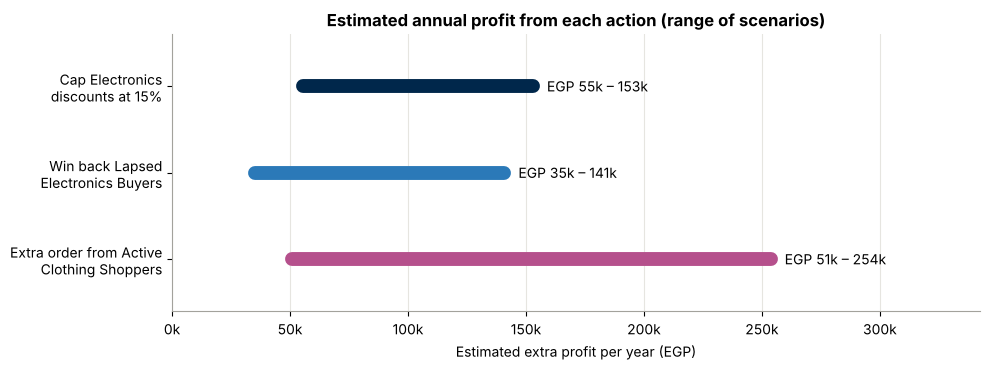

In [14]:
fig, ax = plt.subplots(figsize=(10, 3.8))
labels = ["Cap Electronics\ndiscounts at 15%", "Win back Lapsed\nElectronics Buyers", "Extra order from Active\nClothing Shoppers"]
action_colors = [NAVY, ELECTRONICS, CLOTHING]
for i, (low, high, color) in enumerate(zip(impact["low estimate"], impact["high estimate"], action_colors)):
    ax.plot([low, high], [i, i], color=color, linewidth=10, solid_capstyle="round")
    ax.text(high + 6_000, i, f"EGP {low / 1e3:,.0f}k – {high / 1e3:,.0f}k", va="center", fontsize=10)
ax.set_yticks(range(len(labels)), labels)
ax.set_ylim(-0.6, len(labels) - 0.4)
ax.invert_yaxis()
ax.xaxis.set_major_formatter(thousands)
ax.set_xlim(0, impact["high estimate"].max() * 1.35)
ax.set_xlabel("Estimated extra profit per year (EGP)")
ax.set_title("Estimated annual profit from each action (range of scenarios)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.savefig(images_path / "impact_summary.png", dpi=150, bbox_inches="tight")
plt.show()

In [15]:
total_low = impact["low estimate"].sum()
total_high = impact["high estimate"].sum()
print(f"Combined estimate: EGP {total_low:,.0f} to EGP {total_high:,.0f} a year")
print(f"That is {total_low / profit_2024:.1%} to {total_high / profit_2024:.1%} of 2024 profit "
      f"(EGP {profit_2024:,.0f})")

Combined estimate: EGP 141,544 to EGP 547,305 a year
That is 4.9% to 19.0% of 2024 profit (EGP 2,883,744)

**Together, the three actions could add roughly 5% to 19% to annual profit** (about EGP 140,000 to EGP 550,000). The discount cap is the most certain part: it relies only on transactions we have already observed, and it can't reduce profit.

# Recommendations

| Priority | Recommendation | Evidence | Estimated value |
|---|---|---|---|
| **1** | **Cap Electronics discounts at 15%.** Discounts above that need manager approval. | Electronics margin is 12.5–33%; sales above 15% off lost EGP 55k in 2024 | **+EGP 55k–153k a year**, positive in every scenario |
| **2** | **Use the decision-tree rules as an approval check at checkout** for any exception to the cap. | Catches 95% of loss-making orders (98.7% of the money) with about one review a week | Protects ~EGP 40k a year (overlaps with #1) |
| **3** | **Protect Active Electronics Buyers** with service and bundles, not deeper discounts. | 35% of customers, 70% of revenue, 60% of profit; margin only ~21% | Keeps the largest profit pool; no extra discount cost |
| **4** | **Run a win-back campaign for Lapsed Electronics Buyers**, with offers within the 15% cap. | 340 customers who spent EGP 6.9M but haven't bought in over a year | +EGP 35k–141k a year at 5–20% win-back |
| **5** | **Grow Active Clothing Shoppers** with cross-sell and repeat-visit rewards. | Highest margin (~47%); 21% of profit from 10% of revenue | +EGP 51k–254k a year at 10–50% response |
| **6** | **Re-base loyalty tiers on customer value.** | Platinum members earn no more profit than Bronze | Better-targeted perks; not quantified |
| **7** | **Reactivate cheaply.** Use automated messages for Lapsed Clothing Shoppers and a welcome offer for the 92 registered customers who never purchased. | Small segments with low value per customer | Low cost; not quantified |

### Limitations

- **Customer response is uncertain.** The cap scenarios show a range for this reason. A short pilot in a few stores would measure how many customers accept capped discounts before a chain-wide rollout.
- **Campaign figures are illustrative.** Win-back and cross-sell response rates are assumptions, not measurements, and should be checked with A/B tests.
- **One year of evidence.** All estimates use 2024. Earlier years show the same patterns, which supports the findings, but conditions can change.
- **Synthetic data.** Lotus Group is a fictional company. The figures demonstrate the method and its business use, not the results of a real retailer.